In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [7]:
df = pd.read_csv("dataset.csv")
print(df.info())
print(df.isna().sum())
print(df.duplicated().sum())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [8]:
df = df.drop_duplicates(subset=["track_id"]).copy()


features = [ "acousticness", "danceability", "duration_ms", "energy", "instrumentalness", "liveness", "loudness", "speechiness", "tempo", "valence"]


df = df.dropna(subset=features + ["popularity"]).copy()


df = df.reset_index(drop=True)

#I am separating features form the target
X = df[features].copy()
y = df["popularity"]

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=features,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=features,
    index=X_test.index
)


df.to_csv("spotify_regression_cleaned.csv", index=False)

print("Training size:", X_train_scaled.shape)
print("Testing size:", X_test_scaled.shape)
print(X_train_scaled.head())

Training size: (71792, 10)
Testing size: (17949, 10)
       acousticness  danceability  duration_ms    energy  instrumentalness  \
30418      0.929728      0.016915    -0.031168 -0.652908         -0.536779   
5875      -0.969089     -2.343117     0.254081  1.338204         -0.536521   
68198     -0.966385     -0.820698    -0.389077  1.194033         -0.536513   
57668     -0.817068      1.850609    -0.611248  0.025083         -0.536694   
71420      0.158952      1.052613     0.557717  0.364079         -0.536779   

       liveness  loudness  speechiness     tempo   valence  
30418 -0.586460  0.145934    -0.343737 -0.319299 -1.342302  
5875  -0.701704  0.856036     0.876306 -1.859872 -0.491143  
68198  1.370123  0.988667    -0.282074 -0.237816 -0.209957  
57668 -0.140851  0.765580    -0.182533 -1.133433  0.451211  
71420 -0.099875  0.443830     0.603228 -0.732860  0.629803  


In [9]:

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)


threshold = y_train.median()


y_train_binary = (y_train >= threshold).astype(int)
y_test_binary = (y_test >= threshold).astype(int)

print("Popularity threshold:", threshold)


log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train_binary)


y_pred = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]


print("Accuracy:", accuracy_score(y_test_binary, y_pred))
print("ROC-AUC:", roc_auc_score(y_test_binary, y_prob))

print(classification_report(y_test_binary, y_pred))

print("Confusion matrix:")
print(confusion_matrix(y_test_binary, y_pred))


Popularity threshold: 33.0
Accuracy: 0.5726224302189536
ROC-AUC: 0.6071099804694017
              precision    recall  f1-score   support

           0       0.58      0.46      0.51      8787
           1       0.57      0.68      0.62      9162

    accuracy                           0.57     17949
   macro avg       0.57      0.57      0.57     17949
weighted avg       0.57      0.57      0.57     17949

Confusion matrix:
[[4032 4755]
 [2916 6246]]


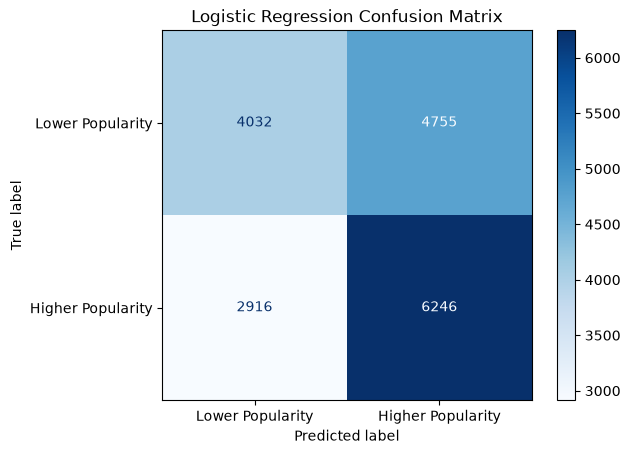

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred,
    display_labels=["Lower Popularity", "Higher Popularity"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

            Feature  Coefficient  Odds Ratio
4  instrumentalness    -0.280715    0.755244
7       speechiness    -0.261864    0.769616
9           valence    -0.239559    0.786975
3            energy    -0.110579    0.895315
0      acousticness    -0.041387    0.959458
2       duration_ms    -0.025626    0.974700
8             tempo     0.028729    1.029146
6          loudness     0.058330    1.060064
5          liveness     0.061384    1.063307
1      danceability     0.258245    1.294657


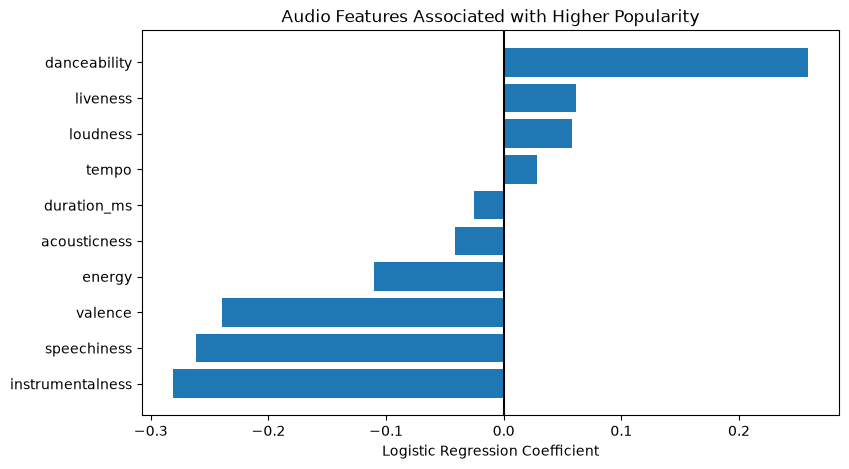

In [11]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": log_model.coef_[0]
})


coefficients["Odds Ratio"] = np.exp(
    coefficients["Coefficient"]
)


coefficients = coefficients.sort_values("Coefficient")

print(coefficients)


plt.figure(figsize=(9, 5))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.axvline(0, color="black")

plt.xlabel("Logistic Regression Coefficient")
plt.title("Audio Features Associated with Higher Popularity")

plt.show()


In [14]:
#Comparing Explicit content status + genre inclusion in prediction 


X_train_extended = X_train_scaled.copy()
X_test_extended = X_test_scaled.copy()


X_train_extended["explicit"] = df.loc[X_train.index, "explicit"].astype(int)
X_test_extended["explicit"] = df.loc[X_test.index, "explicit"].astype(int)


train_genres = pd.get_dummies(
    df.loc[X_train.index, "track_genre"],
    prefix="genre",
    dtype=int
)

test_genres = pd.get_dummies(
    df.loc[X_test.index, "track_genre"],
    prefix="genre",
    dtype=int
)


test_genres = test_genres.reindex(
    columns=train_genres.columns,
    fill_value=0
)


X_train_extended = pd.concat(
    [X_train_extended, train_genres], axis=1
)

X_test_extended = pd.concat(
    [X_test_extended, test_genres], axis=1
)


log_model_extended = LogisticRegression(max_iter=1000)

log_model_extended.fit(X_train_extended, y_train_binary)


y_pred_extended = log_model_extended.predict(X_test_extended)
y_prob_extended = log_model_extended.predict_proba(X_test_extended)[:, 1]

#Compare
print("Original Accuracy:", accuracy_score(y_test_binary, y_pred))
print("Extended Accuracy:", accuracy_score(y_test_binary, y_pred_extended))

print("Original ROC-AUC:", roc_auc_score(y_test_binary, y_prob))
print("Extended ROC-AUC:", roc_auc_score(y_test_binary, y_prob_extended))

print("\nExtended Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred_extended))


Original Accuracy: 0.5726224302189536
Extended Accuracy: 0.7814920051256338
Original ROC-AUC: 0.6071099804694017
Extended ROC-AUC: 0.8631576851427663

Extended Confusion Matrix:
[[6808 1979]
 [1943 7219]]
